# Session 4 - Q2. Contrast Enhancement

Perform the following contrast-enhancement operations:
1. Linear contrast stretching
2. Non-linear contrast stretching
3. Histogram equalization

For each technique, display the original image, enhanced image, original histogram and enhanced histogram.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [2]:
image_path = "input.jpg"
image = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)

if image is None:
    raise FileNotFoundError("Image could not be loaded.")

In [3]:
# Linear contrast stretching
minimum = np.min(image)
maximum = np.max(image)

if maximum > minimum:
    linear_stretch = (
        (image.astype(np.float32) - minimum) / (maximum - minimum) * 255
    ).astype(np.uint8)
else:
    linear_stretch = image.copy()

# Non-linear contrast stretching using gamma transformation
gamma = 0.5
normalized_image = image.astype(np.float32) / 255.0
nonlinear_stretch = (np.power(normalized_image, gamma) * 255).astype(np.uint8)

# Histogram equalization
equalized_image = cv2.equalizeHist(image)

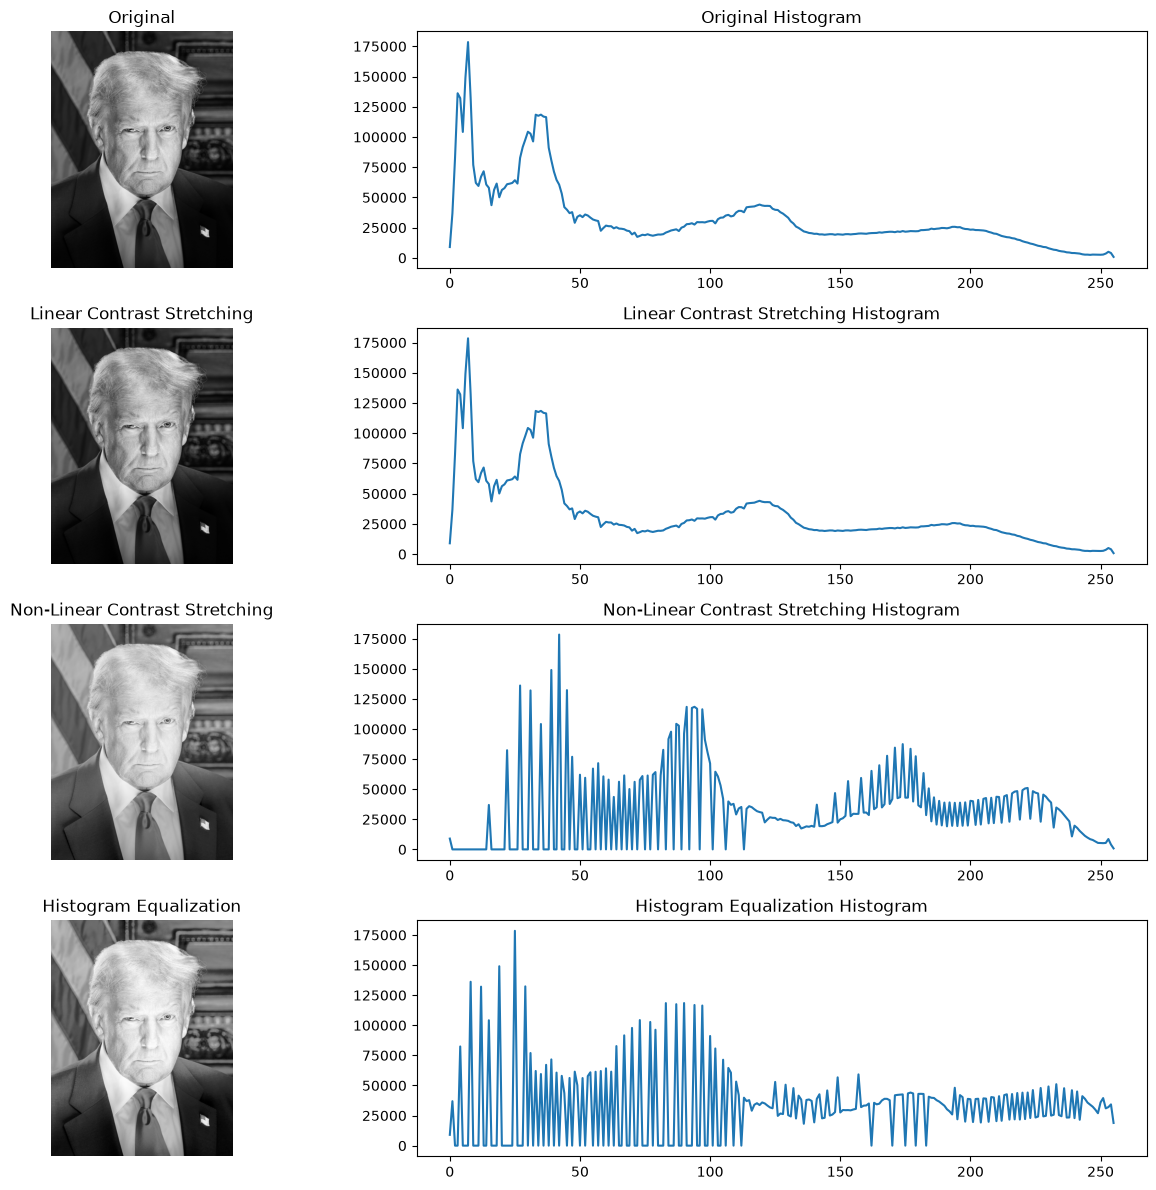

In [4]:
images = [image, linear_stretch, nonlinear_stretch, equalized_image]
titles = [
    "Original", "Linear Contrast Stretching",
    "Non-Linear Contrast Stretching", "Histogram Equalization"
]

plt.figure(figsize=(14, 12))

for i in range(len(images)):
    img = images[i]
    histogram = cv2.calcHist([img], [0], None, [256], [0, 256])

    plt.subplot(4, 2, i * 2 + 1)
    plt.imshow(img, cmap="gray")
    plt.title(titles[i])
    plt.axis("off")

    plt.subplot(4, 2, i * 2 + 2)
    plt.plot(histogram)
    plt.title(titles[i] + " Histogram")

plt.tight_layout()